# Initialized

## Import Library

In [30]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

## Device Keras

In [31]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Status Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")

Status Device: cpu


## Set Seed

Mengunci Seed di awal untuk memenuhi permintaan soal "Seluruh model generatif wajib dilatih menggunakan dataset yang sama, train-val-test split yang seragam, serta penetapan random seed yang tetap (misalnya: torch.manual_seed(42) dan np.random.seed(42))"

In [32]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Load Data MNIST

## Normalize
Dari rentang [0, 1] ke [-1, 1] agar sesuai aktivasi dengan tanh

In [33]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

## Download Dataset

In [34]:
# Download dataset
raw_train = datasets.MNIST(root="./data", train=True, transform=transform, download=True)
raw_test = datasets.MNIST(root="./data", train=False, transform=transform, download=True)
full_dataset = torch.utils.data.ConcatDataset([raw_train, raw_test])

## Data Splitting

In [35]:
total_len = len(full_dataset)
train_size = int(0.80 * total_len)
val_size = int(0.10 * total_len)   
test_size = total_len - train_size - val_size 

train_set, val_set, test_set = torch.utils.data.random_split(
    full_dataset, [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

In [36]:
print(f"- Train Set : {len(train_set)} Images")
print(f"- Val Set   : {len(val_set)} Images")
print(f"- Test Set  : {len(test_set)} Images")

- Train Set : 56000 Images
- Val Set   : 7000 Images
- Test Set  : 7000 Images


## Data Loader

In [37]:
BATCH_SIZE = 128

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

## Denormalize
mengembalikan nilai pixel ke rentang [0, 1] agar mudah ditampilkan sebagai gambar 

In [38]:
def denorm(x):
    return (x * 0.5 + 0.5).clamp(0, 1)

# MLP Classifier

##  1. MCP Classifier Training

### MLP Architecture

In [39]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        # 784 -> 256 -> 64 -> 10
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1) # vektor 1 dimensi
        h1 = F.relu(self.fc1(x)) 
        z = F.relu(self.fc2(h1))
        out = self.fc3(z)
        return out, z, h1

mlp = MLPClassifier().to(device)
opt_mlp = torch.optim.Adam(mlp.parameters(), lr=1e-3)
crit_ce = nn.CrossEntropyLoss()

### Training

In [40]:
for epoch in range(5):
    mlp.train()
    running_loss = 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        opt_mlp.zero_grad() # meng-nol-kan kembali gradient
        out, _, _ = mlp(imgs) # forward pass
        loss = crit_ce(out, labels) # out vs labels untuk loss
        loss.backward() # backward pass
        opt_mlp.step()
        running_loss += loss.item()
    print(f"Epoch [{epoch+1}/5] - CE Loss: {running_loss / len(train_loader):.4f}")

Epoch [1/5] - CE Loss: 0.4335
Epoch [2/5] - CE Loss: 0.1951
Epoch [3/5] - CE Loss: 0.1361
Epoch [4/5] - CE Loss: 0.1111
Epoch [5/5] - CE Loss: 0.0876


## 2. Top Down Weight Transposition
Membuat gambar dengan membalik arah jalan dari label menuju piksel

### Transpose weight matrix (W^T)

In [41]:
W1 = mlp.fc1.weight.data  
W2 = mlp.fc2.weight.data  
W3 = mlp.fc3.weight.data  

target_class = torch.zeros(1, 10).to(device)
target_class[0, 3] = 1.0  

z_trans = F.relu(torch.matmul(target_class, W3))  
h1_trans = F.relu(torch.matmul(z_trans, W2))      # [1, 64] x [64, 256] -> [1, 256]
x_recon_wT = torch.sigmoid(torch.matmul(h1_trans, W1)).view(1, 28, 28)

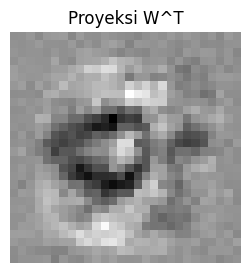

In [42]:
plt.figure(figsize=(3, 3))
plt.imshow(x_recon_wT[0].cpu().numpy(), cmap='gray')
plt.title("Proyeksi W^T")
plt.axis('off')
plt.show()

## 3. Latent Transpose Projection

In [43]:
sample_img, sample_label = next(iter(test_loader))
sample_img = sample_img[0:1].to(device) 

# forward
with torch.no_grad():
    _, z_sample, _ = mlp(sample_img)

# 2.backward (W2^T dan W1^T)
h1_latent_trans = F.relu(torch.matmul(z_sample, W2))
x_recon_zT = torch.sigmoid(torch.matmul(h1_latent_trans, W1)).view(1, 28, 28)

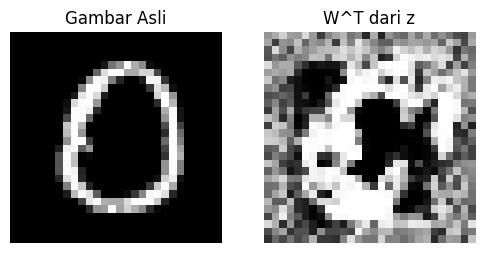

In [44]:
plt.figure(figsize=(6, 3))

# Gambar asli
plt.subplot(1, 2, 1)
plt.imshow(denorm(sample_img[0, 0]).cpu().numpy(), cmap='gray')
plt.title("Gambar Asli")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(x_recon_zT[0].cpu().numpy(), cmap='gray')
plt.title("W^T dari z")
plt.axis('off')

plt.show()

## 4. Frozen Latent Decoding
Jaringan decoder khsusus yang belajar mengkonstruksi kembali image asli dari representasi laten classifier.

### Freezing MLP Classifier Weight 
Supaya representasi laten tidak berubah

In [45]:
for param in mlp.parameters():
    param.requires_grad = False

### New Decoder (64 -> 256 -> 784)

In [46]:
class LatentDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Tanh()
        )
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

decoder_mlp = LatentDecoder().to(device)
opt_dec = torch.optim.Adam(decoder_mlp.parameters(), lr=1e-3)

### Training Decoder with MSE Loss
Dilatih untuk meminimalkan selisih piksel (Mean Squared Error) antara citra hasil tebakan decoder dengan citra asli.

In [47]:
for epoch in range(5):
    decoder_mlp.train()
    running_loss = 0.0
    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        with torch.no_grad():
            _, z_feat, _ = mlp(imgs)
        
        opt_dec.zero_grad()
        rec = decoder_mlp(z_feat)
        loss = F.mse_loss(rec, imgs)
        loss.backward()
        opt_dec.step()
        running_loss += loss.item()
    print(f"Epoch [{epoch+1}/5] - Decoder MSE Loss: {running_loss / len(train_loader):.4f}")

Epoch [1/5] - Decoder MSE Loss: 0.1457
Epoch [2/5] - Decoder MSE Loss: 0.0998
Epoch [3/5] - Decoder MSE Loss: 0.0912
Epoch [4/5] - Decoder MSE Loss: 0.0862
Epoch [5/5] - Decoder MSE Loss: 0.0829


In [48]:
decoder_mlp.eval()
with torch.no_grad():
    rec_frozen_sample = decoder_mlp(z_sample)

### Comparing Result with the Real Image

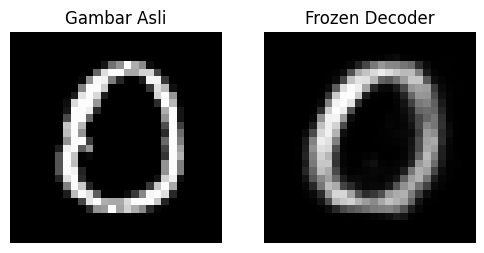

In [49]:
plt.figure(figsize=(6, 3))

# Gambar Asli
plt.subplot(1, 2, 1)
plt.imshow(denorm(sample_img[0, 0]).cpu().numpy(), cmap='gray')
plt.title("Gambar Asli")
plt.axis('off')

# Hasil Rekonstruksi dari Frozen Latent Decoder
plt.subplot(1, 2, 2)
plt.imshow(denorm(rec_frozen_sample[0, 0]).cpu().numpy(), cmap='gray')
plt.title("Frozen Decoder")
plt.axis('off')

plt.show()

## 5. Prior Sampling at Latents MLP

### Vektor laten z from test set

In [50]:
mlp_latents = []
with torch.no_grad():
    for imgs, _ in test_loader:
        imgs = imgs.to(device)
        _, z_batch, _ = mlp(imgs)
        mlp_latents.append(z_batch.cpu())

mlp_latents = torch.cat(mlp_latents, dim=0)

### Mean & Standard Deviation

In [51]:
mu_z = mlp_latents.mean(dim=0)
std_z = mlp_latents.std(dim=0)

### Random Spot

In [52]:
z_rand = (mu_z + std_z * torch.randn(1, 64)).to(device)

# Decode 
with torch.no_grad():
    sample_random_mlp = decoder_mlp(z_rand)

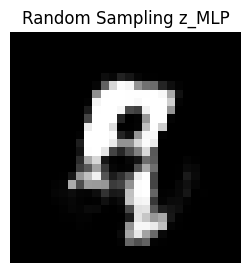

In [53]:
plt.figure(figsize=(3, 3))
plt.imshow(denorm(sample_random_mlp[0, 0]).cpu().numpy(), cmap='gray')
plt.title("Random Sampling z_MLP")
plt.axis('off')
plt.show()